# A 1D diffusion model

Here we develop a one-dimensional numerical model of diffusion. 
It assumes a constant diffusivity.
It used a regular grid. 
It has a step function for an initial profile. 
It has fixed boundary conditions. 

The diffusion equation:

$$ \frac{\partial z}{\partial t} = D\frac{\partial^2 z}{\partial x^2} $$

Here, $z$ is elevation, $t$ is time, $x$ is the spatial dimension, and $D$ is a transport-rate coefficient, sometimes called hillslope diffusivity---with dimensions length squared per time. 

The discretized version of the diffusion equation that we'll solve with our model is: $$ z^{t+1}_x = z^t_x + {D \Delta t \over \Delta x^2} (z^t_{x+1} - 2z^t_x + z^t_{x-1}) $$

This is the forward in time centered in space (FTCS) scheme that you can look up in a textbook.

We'll use two libraries, NumPy (for arrays) and Matplotlib (for plots), that aren't part of the core Python distribution. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Start by setting two fixed model parameters---the diffusivity and the size of the model domain. 

In [3]:
D = 100 #diffusivity
Lx = 300 #model domain

Next, set up the grid using a NumPy array

In [4]:
dx = 0.5 # grid spacing
x = np.arange(start=0, stop=Lx, step=dx)
nx=len(x) #number of grid nodes

In [5]:
x

array([  0. ,   0.5,   1. ,   1.5,   2. ,   2.5,   3. ,   3.5,   4. ,
         4.5,   5. ,   5.5,   6. ,   6.5,   7. ,   7.5,   8. ,   8.5,
         9. ,   9.5,  10. ,  10.5,  11. ,  11.5,  12. ,  12.5,  13. ,
        13.5,  14. ,  14.5,  15. ,  15.5,  16. ,  16.5,  17. ,  17.5,
        18. ,  18.5,  19. ,  19.5,  20. ,  20.5,  21. ,  21.5,  22. ,
        22.5,  23. ,  23.5,  24. ,  24.5,  25. ,  25.5,  26. ,  26.5,
        27. ,  27.5,  28. ,  28.5,  29. ,  29.5,  30. ,  30.5,  31. ,
        31.5,  32. ,  32.5,  33. ,  33.5,  34. ,  34.5,  35. ,  35.5,
        36. ,  36.5,  37. ,  37.5,  38. ,  38.5,  39. ,  39.5,  40. ,
        40.5,  41. ,  41.5,  42. ,  42.5,  43. ,  43.5,  44. ,  44.5,
        45. ,  45.5,  46. ,  46.5,  47. ,  47.5,  48. ,  48.5,  49. ,
        49.5,  50. ,  50.5,  51. ,  51.5,  52. ,  52.5,  53. ,  53.5,
        54. ,  54.5,  55. ,  55.5,  56. ,  56.5,  57. ,  57.5,  58. ,
        58.5,  59. ,  59.5,  60. ,  60.5,  61. ,  61.5,  62. ,  62.5,
        63. ,  63.5,

Set the initial conditions for the model. The elevation $z$ is a step function with a high value to the left, a low value on the right, and a cliff in the middle of the domain.

In [6]:
z = np.zeros_like(x)
z_left = 500
z_right = 0
z[x<=Lx/2] = z_left
z[x >Lx/2] = z_right

Plot the initial profile.

Text(0.5, 1.0, 'initial hillslope profile')

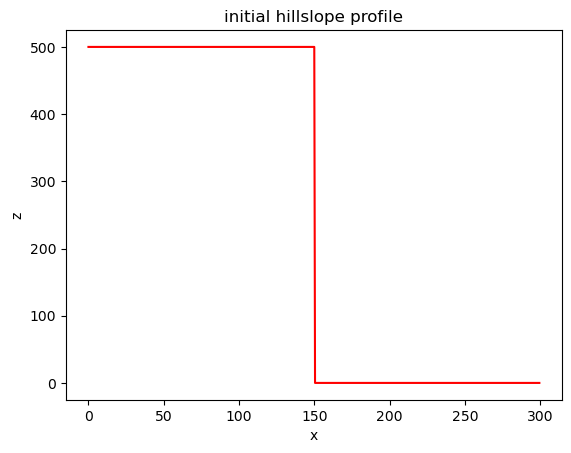

In [7]:
plt.figure()
plt.plot(x, z, "r")
plt.xlabel("x")
plt.ylabel("z")
plt.title("initial hillslope profile")

Set up time stepping for the model.
Calculate a stable time step from a stability criterion.

In [8]:
nt = 5000 #number of time steps
dt = 0.5*dx**2/D #time step

Loop over the time steps of the model, solving the diffusion equation using the FTCS scheme described above. Note the use of array operations on the elvation $z$. The boundary conditions remain fixed in each time step.

In [10]:
for t in range(0, nt):
	z[1:-1] += D * dt / dx ** 2 * (z[:-2] - 2*z[1:-1] + z[2:])

plot the result!

Text(0.5, 1.0, 'final hillslope profile')

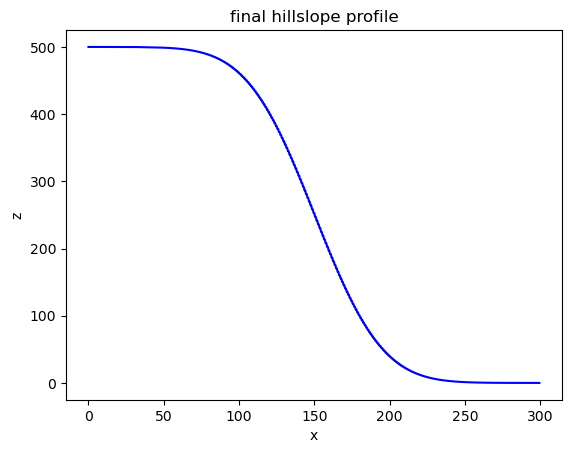

In [11]:
plt.figure()
plt.plot(x, z, "b")
plt.xlabel("x")
plt.ylabel("z")
plt.title("final hillslope profile")